In [139]:
import numpy as np
import matplotlib.pyplot as plt

In [140]:
SEED = 17
np.random.seed(SEED)

# Dimension
dim = 1
num_samples = 7

# Generate random traning data
w = np.random.rand(1, dim) * 2          # Note that we need w to be a 2D array for matrix multiplication to get correct shape

e = np.random.normal(0, 1, size=(num_samples, dim)) * 0.1
e_test = np.random.normal(0, 1, size=(num_samples, dim)) * 0.1

x_train = np.random.rand(num_samples, dim)
y_train = x_train @ w + e

x_test = np.random.rand(num_samples, dim)
y_test = x_test @ w + e_test

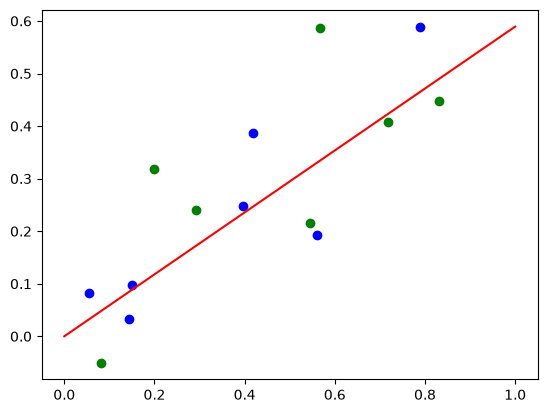

In [141]:
x_grid = np.linspace(0, 1, num_samples).reshape(-1, 1)
y_grid = x_grid @ w

plt.scatter(x_train, y_train, label='Training Data', color='blue')
plt.scatter(x_test, y_test, label='Test Data', color='green')
plt.plot(x_grid, y_grid, label='True Function', color='red')

In [142]:
# w = y(XT X)^-1 XT
from numpy.linalg import pinv

print(np.shape(x_train @ x_train.T))
print(np.shape(y_train))
print(np.shape(x_train.T))

w_pred = pinv(x_train) @ y_train      # pinv is moore-penrose pseudoinverse
y_train_pred = x_train @ w_pred

(7, 7)
(7, 1)
(1, 7)


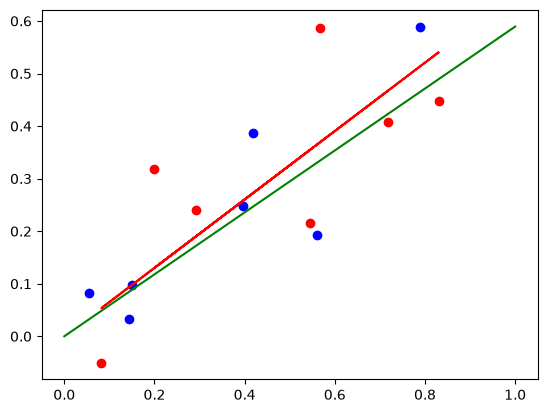

In [143]:
y_test_pred = x_test @ w_pred

plt.scatter(x_train, y_train, label='Training Data', color='blue')
plt.scatter(x_test, y_test, label='Test Data', color='red')
plt.plot(x_grid, y_grid, label='True Function', color='green')
plt.plot(x_test, y_test_pred, label='Predicted Function', color='red')

In [144]:
# Calculate the mean squared error
mse = np.mean((y_test_pred - y_test) ** 2)
print(mse)

# Calculate the r2 score
from sklearn.metrics import r2_score
train_r2 = r2_score(y_train, y_train_pred) 
print(train_r2)
test_r2 = r2_score(y_test, y_test_pred)
print(test_r2)

0.018224607059257554
0.7669479989264483
0.4853501739413988


In [145]:
from sklearn.linear_model import LinearRegression

reg = LinearRegression().fit(x_train, y_train)

y_train_pred_sk = reg.predict(x_train)
y_test_pred_sk = reg.predict(x_test)

sk_r2_train = r2_score(y_train, y_train_pred_sk)
print(sk_r2_train)
sk_r2_test = r2_score(y_test, y_test_pred_sk)
print(sk_r2_test)

0.7670915325892962
0.48154979449626567


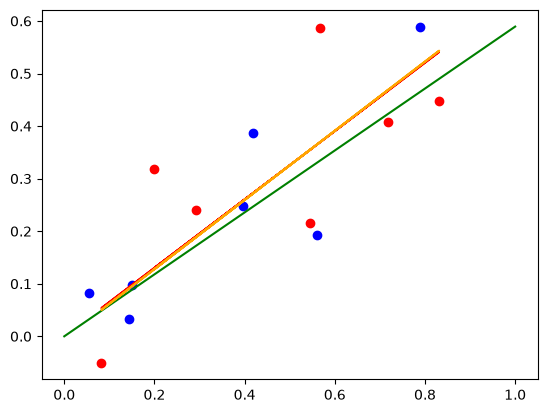

In [146]:
plt.scatter(x_train, y_train, label='Training Data', color='blue')
plt.scatter(x_test, y_test, label='Test Data', color='red')
plt.plot(x_grid, y_grid, label='True Function', color='green')
plt.plot(x_test, y_test_pred, label='Predicted Function', color='red')
plt.plot(x_test, y_test_pred_sk, label='Predicted Function (sklearn)', color='orange')
